In [14]:
import numpy as np
import os
import cv2
import matplotlib.pyplot as plt
import random
import time
import numpy as np
import tensorflow as tf
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from keras.utils import to_categorical

In [15]:
def assign_label(flower_type):
    if flower_type == 'daisy':
        return 1
    elif flower_type == 'dandelion':
        return 2
    elif flower_type == 'rose':
        return 3
    elif flower_type == 'sunflower':
        return 4
    elif flower_type == 'tulip':
        return 0


In [16]:


classes = ['tulip', 'daisy', 'dandelion', 'rose', 'sunflower']

X = []
Z = []


inputdataset = "flowers"

for flower in os.listdir(inputdataset):
    flower_path = os.path.join(inputdataset, flower)  

    if not os.path.isdir(flower_path):  
        continue

    for filename in os.listdir(flower_path):
        img_path = os.path.join(flower_path, filename)  
        img = cv2.imread(img_path, cv2.IMREAD_COLOR)

        if img is None:
            print(f"Warning: {img_path} could not be loaded.")
            continue
        img = cv2.resize(img, (224, 224))
        label = assign_label(flower)
        X.append(np.array(img / 255))
        Z.append(label)




In [17]:
X = np.array(X)
Z = np.array(Z)

Y = to_categorical(Z, 5)

print(f"Shape of X: {X.shape}")
print(f"Shape of Y: {Y.shape}")
print(f"Shape of Z: {Z.shape}")

Shape of X: (4317, 224, 224, 3)
Shape of Y: (4317, 5)
Shape of Z: (4317,)


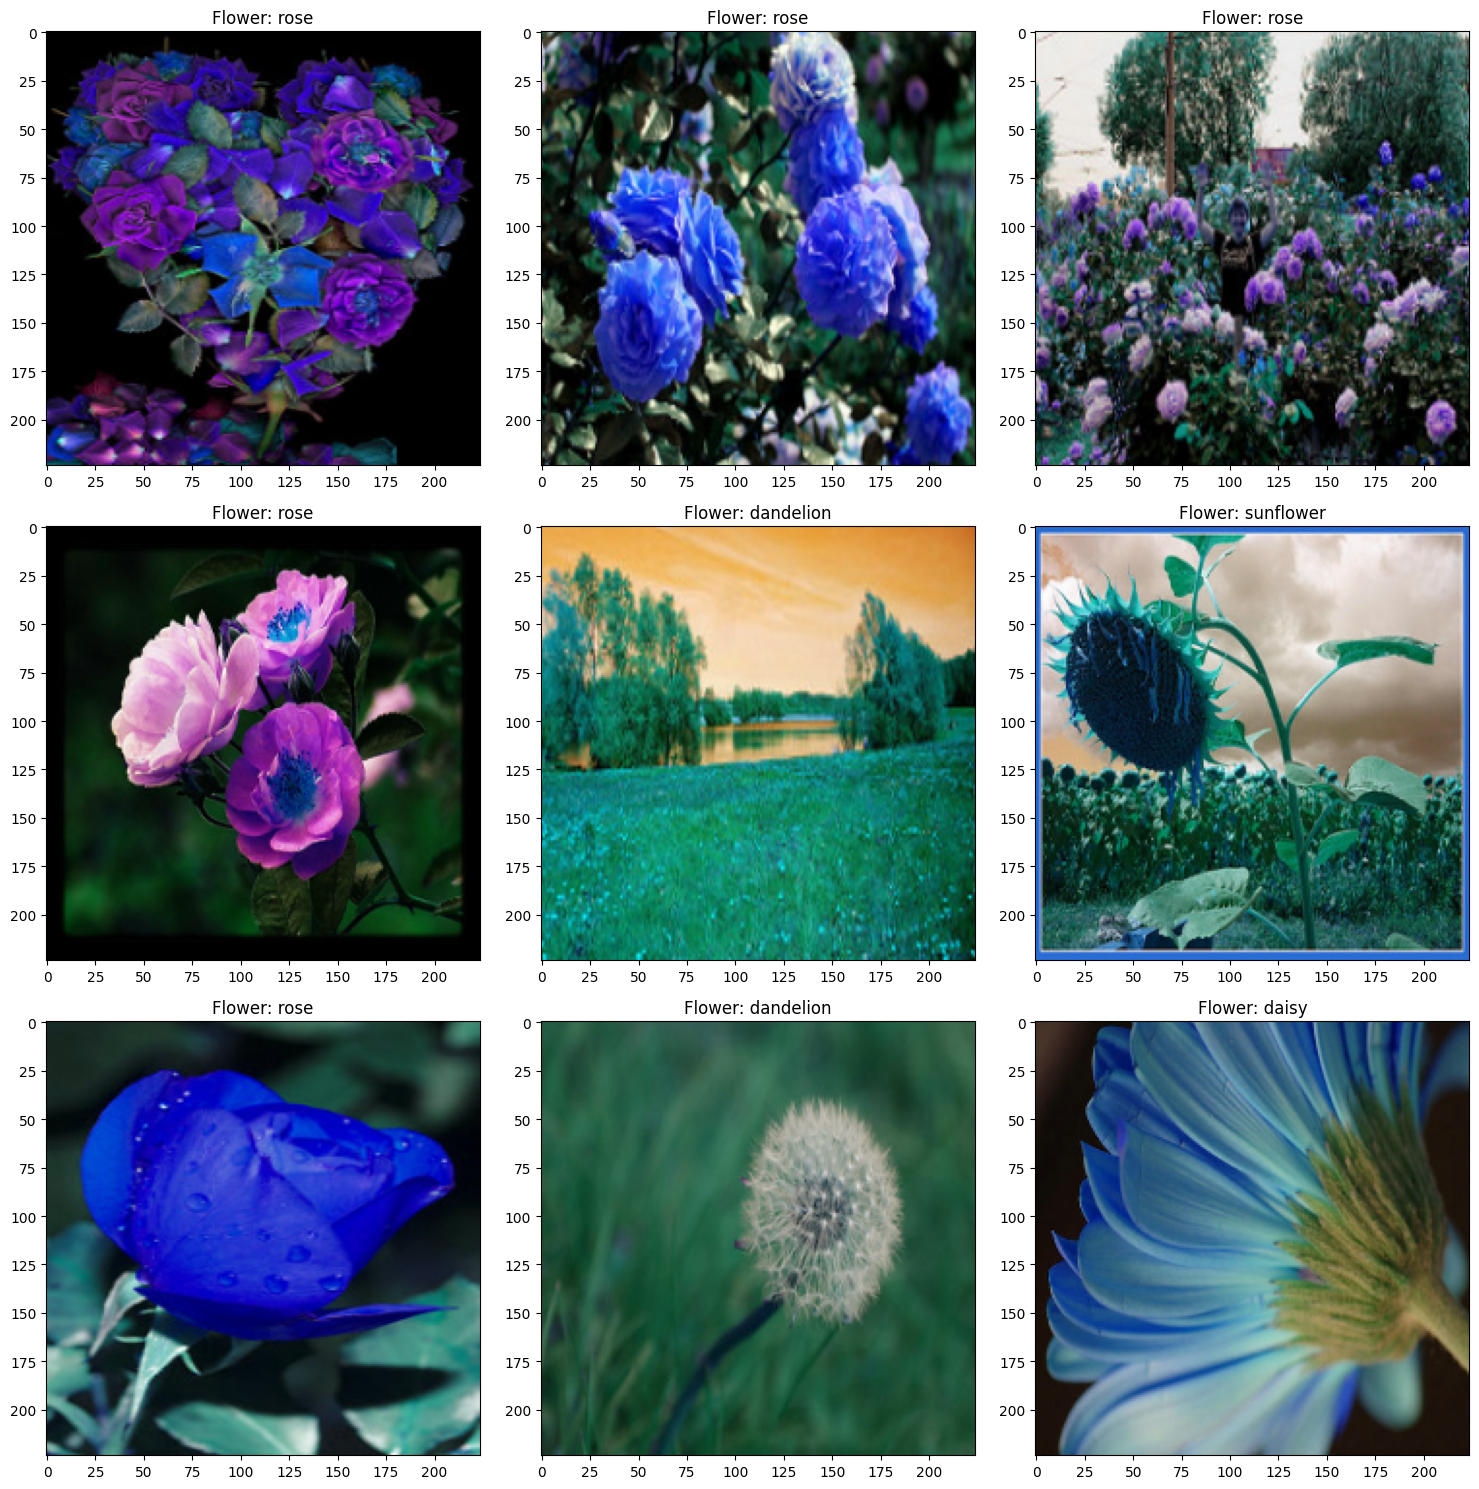

In [18]:
figure, axes = plt.subplots(3, 3)
figure.set_size_inches(15, 15)

for row in range(3):
    for col in range(3):
        index = random.randint(0, len(X) - 1)

        image = X[index]
        flower_label = Z[index]

        axes[row, col].imshow(image)
        axes[row, col].set_title(f"Flower: {classes[flower_label]}")

plt.tight_layout()
plt.show()

In [19]:
indices = np.arange(len(X))
np.random.shuffle(indices)

train_indices = indices[:500]
test_indices = indices[500:750]

X_train = X[train_indices]
Y_train = Y[train_indices]
X_test = X[test_indices]
Y_test = Y[test_indices]

print(f"Shape of X_train: {X_train.shape}")
print(f"Shape of X_test: {X_test.shape}")
print(f"Shape of Y_train: {Y_train.shape}")
print(f"Shape of Y_test: {Y_test.shape}")

Shape of X_train: (500, 224, 224, 3)
Shape of X_test: (250, 224, 224, 3)
Shape of Y_train: (500, 5)
Shape of Y_test: (250, 5)


In [20]:
# Define the model
model = Sequential()

# Add convolutional layers
model.add(Conv2D(32, (3, 3), activation='relu', input_shape=(224, 224, 3)))
model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Conv2D(128, (3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

# Flatten the layers
model.add(Flatten())

# Add fully connected layers
model.add(Dense(128, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(5, activation='softmax'))

# Compile the model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Train the model with time estimation
epochs = 10
batch_size = 32
start_time = time.time()

for epoch in range(epochs):
    epoch_start_time = time.time()
    model.fit(X_train, Y_train, epochs=1, batch_size=batch_size, validation_data=(X_test, Y_test))
    epoch_end_time = time.time()
    
    elapsed_time = epoch_end_time - start_time
    avg_epoch_time = elapsed_time / (epoch + 1)
    remaining_time = avg_epoch_time * (epochs - epoch - 1)
    
    print(f"Epoch {epoch + 1}/{epochs} completed in {epoch_end_time - epoch_start_time:.2f} seconds.")
    print(f"Estimated remaining time: {remaining_time:.2f} seconds.")

total_time = time.time() - start_time
print(f"Total training time: {total_time:.2f} seconds.")

16/16 [==============================] - 26s 2s/step - loss: 1.7314 - accuracy: 0.2700 - val_loss: 1.5289 - val_accuracy: 0.3040
Epoch 1/10 completed in 29.23 seconds.
Estimated remaining time: 263.09 seconds.
16/16 [==============================] - 27s 2s/step - loss: 1.4854 - accuracy: 0.3480 - val_loss: 1.4762 - val_accuracy: 0.3880
Epoch 2/10 completed in 27.44 seconds.
Estimated remaining time: 226.71 seconds.
16/16 [==============================] - 24s 1s/step - loss: 1.3376 - accuracy: 0.4240 - val_loss: 1.3710 - val_accuracy: 0.4120
Epoch 3/10 completed in 24.17 seconds.
Estimated remaining time: 188.65 seconds.
16/16 [==============================] - 25s 2s/step - loss: 1.1533 - accuracy: 0.5300 - val_loss: 1.3607 - val_accuracy: 0.4480
Epoch 4/10 completed in 26.12 seconds.
Estimated remaining time: 160.46 seconds.
16/16 [==============================] - 29s 2s/step - loss: 1.1031 - accuracy: 0.5660 - val_loss: 1.3750 - val_accuracy: 0.4480
Epoch 5/10 completed in 29.80 s